In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout,
    BatchNormalization,
    RandomRotation,
    RandomZoom,
    RandomTranslation
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

print("TensorFlow Version:", tf.__version__)
print("NumPy Version:", np.__version__)

tf.keras.utils.set_random_seed(42)

TensorFlow Version: 2.21.0
NumPy Version: 1.26.4


In [3]:
# Define dataset directory

BASE_DIR = Path.cwd()

DATA_DIR = BASE_DIR / "dataset"

# Dataset paths

TRAIN_PATH = DATA_DIR / "sign_mnist_train.csv"

TEST_PATH = DATA_DIR / "sign_mnist_test.csv"

# Check files

if not TRAIN_PATH.exists():
    raise FileNotFoundError(f"Training file not found: {TRAIN_PATH}")

if not TEST_PATH.exists():
    raise FileNotFoundError(f"Testing file not found: {TEST_PATH}")

# Load datasets

train_df = pd.read_csv(TRAIN_PATH)

test_df = pd.read_csv(TEST_PATH)

print("Training Dataset Shape:", train_df.shape)

print("Testing Dataset Shape:", test_df.shape)

print("\nFirst Five Rows:")

display(train_df.head())

Training Dataset Shape: (27455, 785)
Testing Dataset Shape: (7172, 785)

First Five Rows:


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


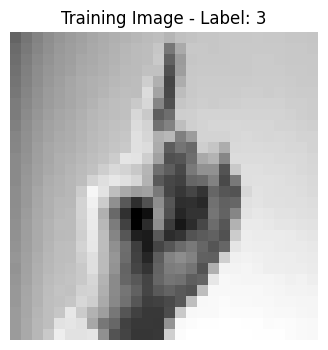

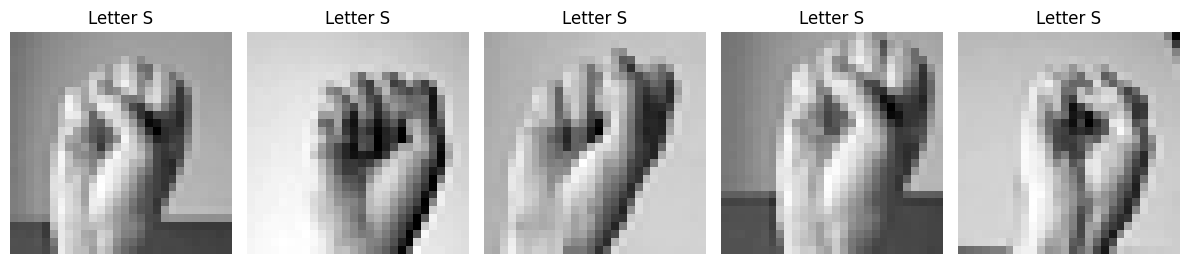

Minimum pixel value: 0
Maximum pixel value: 255


In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Display one original training image
image = train_df.iloc[0, 1:].values.reshape(28, 28)

plt.figure(figsize=(4, 4))
plt.imshow(image, cmap="gray")
plt.title(f"Training Image - Label: {train_df.iloc[0, 0]}")
plt.axis("off")
plt.show()

# Display 5 training images of letter S
s_images = train_df[train_df["label"] == 18].head(5)

fig, axes = plt.subplots(1, 5, figsize=(12, 3))

for i, (_, row) in enumerate(s_images.iterrows()):
    pixels = row.iloc[1:].values.reshape(28, 28)
    axes[i].imshow(pixels, cmap="gray")
    axes[i].set_title("Letter S")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

# Check pixel values
print("Minimum pixel value:", train_df.iloc[:, 1:].values.min())
print("Maximum pixel value:", train_df.iloc[:, 1:].values.max())

In [4]:
print("Training Dataset Information")

print(train_df.info())

print("\nMissing Values:")

print(train_df.isnull().sum().sum())

print("\nAvailable Labels:")

print(sorted(train_df["label"].unique()))

print("\nLabel Distribution:")

print(train_df["label"].value_counts().sort_index())

Training Dataset Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27455 entries, 0 to 27454
Columns: 785 entries, label to pixel784
dtypes: int64(785)
memory usage: 164.4 MB
None

Missing Values:
0

Available Labels:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24]

Label Distribution:
label
0     1126
1     1010
2     1144
3     1196
4      957
5     1204
6     1090
7     1013
8     1162
10    1114
11    1241
12    1055
13    1151
14    1196
15    1088
16    1279
17    1294
18    1199
19    1186
20    1161
21    1082
22    1225
23    1164
24    1118
Name: count, dtype: int64


In [5]:
# Separate training labels

y_train = train_df["label"].values

# Separate training images

X_train = train_df.drop(
    "label",
    axis=1
).values

# Separate testing labels

y_test = test_df["label"].values

# Separate testing images

X_test = test_df.drop(
    "label",
    axis=1
).values

print("X_train:", X_train.shape)

print("y_train:", y_train.shape)

print("X_test:", X_test.shape)

print("y_test:", y_test.shape)

X_train: (27455, 784)
y_train: (27455,)
X_test: (7172, 784)
y_test: (7172,)


In [6]:
# Convert into float32

X_train = X_train.astype("float32")

X_test = X_test.astype("float32")

# Normalize pixel values

X_train = X_train / 255.0

X_test = X_test / 255.0

# Reshape images into 28x28 grayscale format

X_train = X_train.reshape(-1, 28, 28, 1)

X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Images Shape:", X_train.shape)

print("Testing Images Shape:", X_test.shape)

print("Minimum Pixel Value:", X_train.min())

print("Maximum Pixel Value:", X_train.max())

Training Images Shape: (27455, 28, 28, 1)
Testing Images Shape: (7172, 28, 28, 1)
Minimum Pixel Value: 0.0
Maximum Pixel Value: 1.0


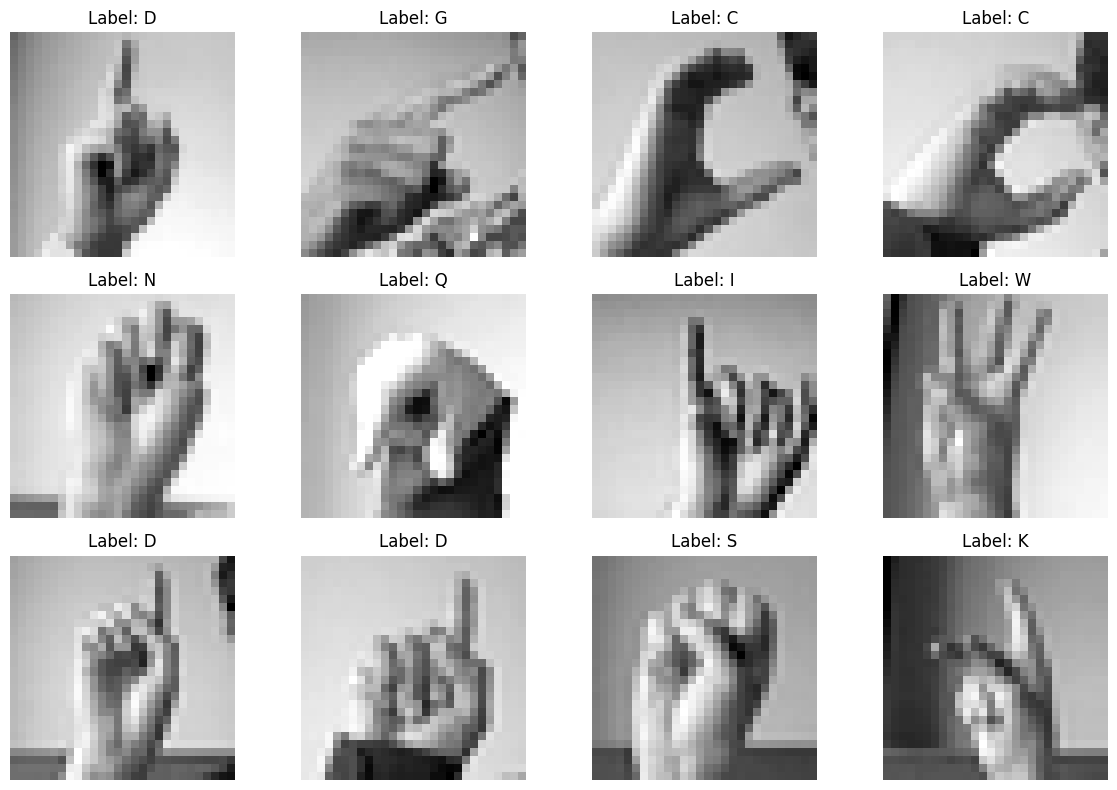

In [7]:
# Correct label mapping for Sign Language MNIST

def label_to_letter(label):

    if label == 9 or label < 0 or label > 24:
        return "Unknown"

    return chr(label + 65)


plt.figure(figsize=(12, 8))

for i in range(12):

    plt.subplot(3, 4, i + 1)

    plt.imshow(
        X_train[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        "Label: " + label_to_letter(int(y_train[i]))
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

In [8]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

print("Training Data:", X_train.shape)

print("Validation Data:", X_val.shape)

print("Testing Data:", X_test.shape)

Training Data: (23336, 28, 28, 1)
Validation Data: (4119, 28, 28, 1)
Testing Data: (7172, 28, 28, 1)


In [9]:
# Initialize CNN Model

model = Sequential()

# Input Layer

model.add(
    Input(shape=(28, 28, 1))
)

# Data Augmentation

model.add(
    RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    )
)

model.add(
    RandomZoom(0.08)
)

model.add(
    RandomRotation(0.03)
)

# First Convolutional Block

model.add(
    Conv2D(
        32,
        (3, 3),
        activation="relu",
        padding="same"
    )
)

model.add(BatchNormalization())

model.add(MaxPooling2D((2, 2)))

# Second Convolutional Block

model.add(
    Conv2D(
        64,
        (3, 3),
        activation="relu",
        padding="same"
    )
)

model.add(BatchNormalization())

model.add(MaxPooling2D((2, 2)))

# Third Convolutional Block

model.add(
    Conv2D(
        128,
        (3, 3),
        activation="relu",
        padding="same"
    )
)

model.add(BatchNormalization())

# Flatten

model.add(Flatten())

# Fully Connected Layer

model.add(
    Dense(
        128,
        activation="relu"
    )
)

model.add(Dropout(0.4))

# Output Layer

model.add(
    Dense(
        25,
        activation="softmax"
    )
)

# Display Architecture

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_translation              │ (None, 28, 28, 1)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 28, 28, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │         3,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 899,737 (3.43 MB)

 Trainable params: 899,289 (3.43 MB)

 Non-trainable params: 448 (1.75 KB)

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [11]:
# Model save path

MODEL_PATH = "sign_language_cnn_model_fixed.keras"

# Early stopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True
)

# Learning rate reduction

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

# Save best model

checkpoint = ModelCheckpoint(
    MODEL_PATH,
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

callbacks = [
    early_stopping,
    reduce_lr,
    checkpoint
]

print("Callbacks Created Successfully!")

Callbacks Created Successfully!


In [ ]:
history = model.fit(

    X_train,

    y_train,

    epochs=30,

    batch_size=64,

    validation_data=(
        X_val,
        y_val
    ),

    callbacks=callbacks,

    verbose=1

)

print("\nCNN Training Completed!")

Epoch 1/30
364/365 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.5103 - loss: 1.6838
Epoch 1: val_accuracy improved from None to 0.57854, saving model to sign_language_cnn_model_fixed.keras
365/365 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.7151 - loss: 0.9194 - val_accuracy: 0.5785 - val_loss: 2.1193 - learning_rate: 0.0010
Epoch 2/30
365/365 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9331 - loss: 0.2003
Epoch 2: val_accuracy improved from 0.57854 to 0.98908, saving model to sign_language_cnn_model_fixed.keras
365/365 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - accuracy: 0.9473 - loss: 0.1582 - val_accuracy: 0.9891 - val_loss: 0.0344 - learning_rate: 0.0010
Epoch 3/30
364/365 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.9689 - loss: 0.0906
Epoch 3: val_accuracy did not improve from 0.98908
365/365 ━━━━━━━━━━━━━━━━━━━━ 14s 38ms/step - accuracy: 0.9724 - loss: 0.0818 - val_accuracy: 0.9412 - val_loss: 0.2188 - learning_rate: 0.0010
Epoch 4/30
364/365 ━━━━━━━━━━━━━━━━━━━━ 0s 39m

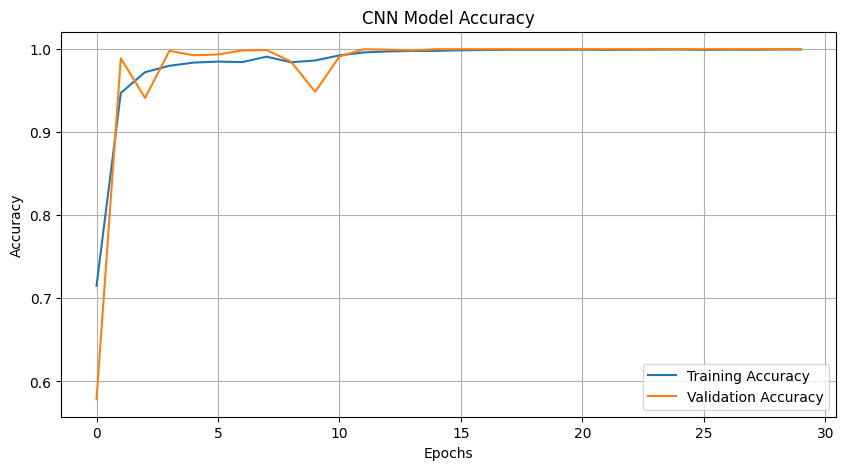

In [13]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Model Accuracy")

plt.xlabel("Epochs")

plt.ylabel("Accuracy")

plt.legend()

plt.grid()

plt.show()

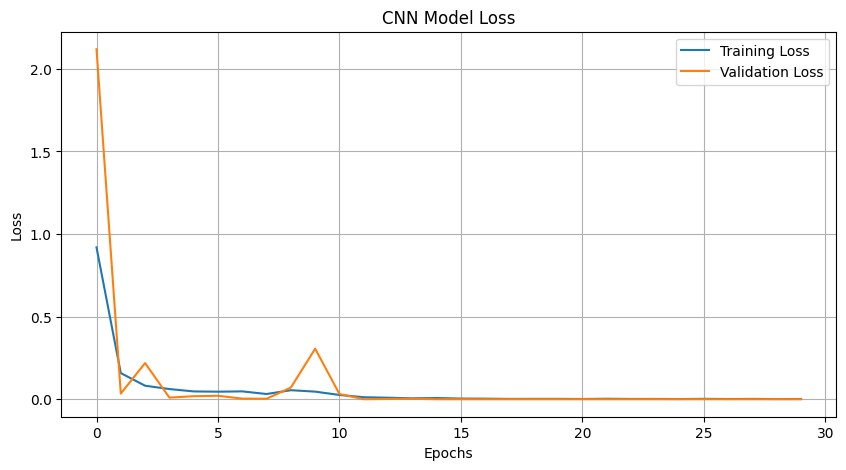

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Model Loss")

plt.xlabel("Epochs")

plt.ylabel("Loss")

plt.legend()

plt.grid()

plt.show()

In [15]:
# Load best saved model

model = tf.keras.models.load_model(
    MODEL_PATH,
    compile=False
)

# Compile for evaluation

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Evaluate

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("\n================================")

print("CNN MODEL EVALUATION")

print("================================")

print("Test Loss:", test_loss)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9895 - loss: 0.0403

CNN MODEL EVALUATION
Test Loss: 0.04027043282985687
Test Accuracy: 98.95 %


In [16]:
predictions = model.predict(
    X_test,
    verbose=1
)

predicted_labels = np.argmax(
    predictions,
    axis=1
)

print("Predictions Generated Successfully!")

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
Predictions Generated Successfully!


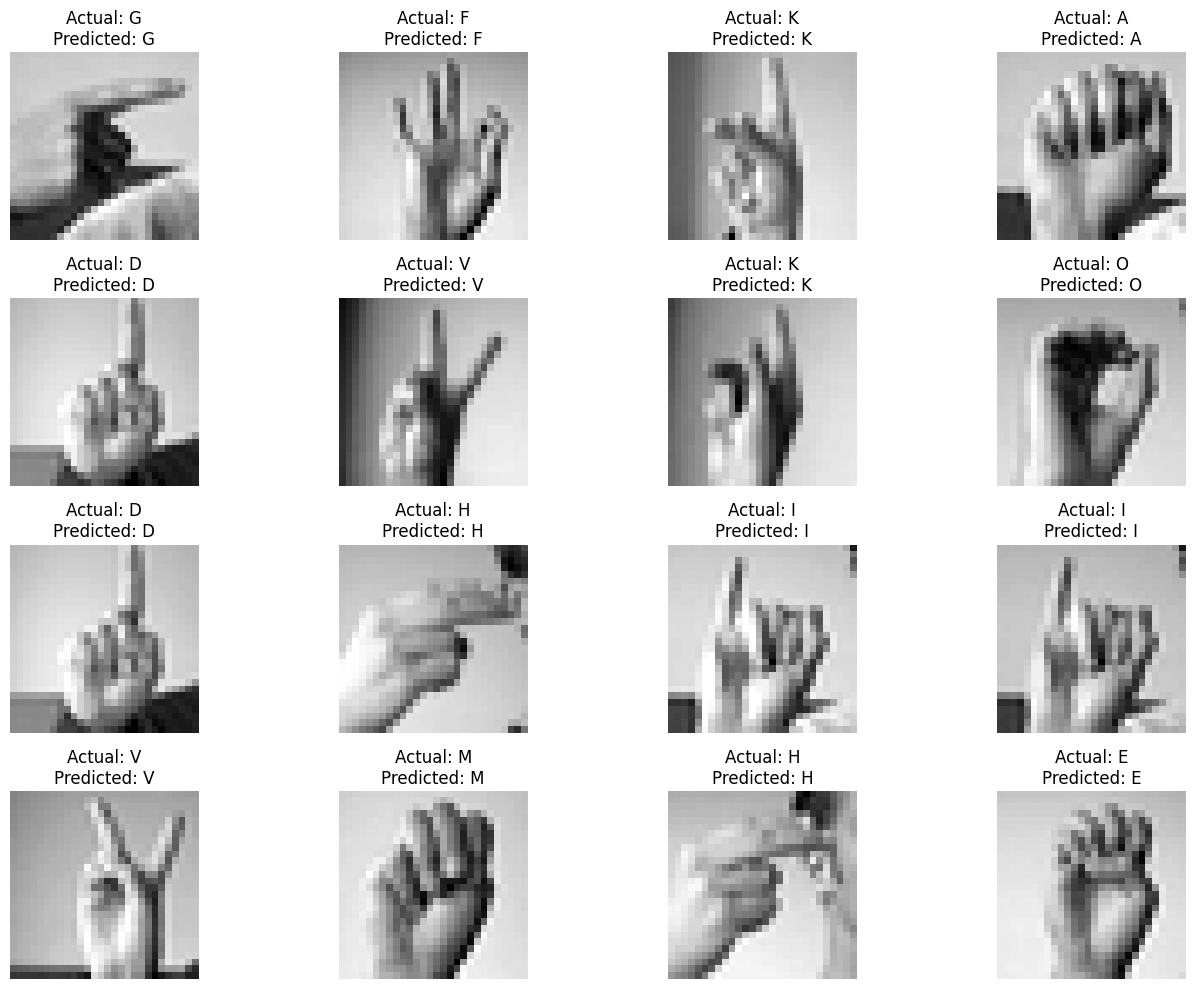

In [17]:
plt.figure(figsize=(14, 10))

for i in range(16):

    plt.subplot(4, 4, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap="gray"
    )

    actual = label_to_letter(
        int(y_test[i])
    )

    predicted = label_to_letter(
        int(predicted_labels[i])
    )

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

In [18]:
print(
    classification_report(
        y_test,
        predicted_labels,
        labels=list(range(25)),
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00       331
           1       1.00      1.00      1.00       432
           2       1.00      1.00      1.00       310
           3       1.00      1.00      1.00       245
           4       1.00      1.00      1.00       498
           5       1.00      1.00      1.00       247
           6       0.98      0.99      0.98       348
           7       1.00      0.98      0.99       436
           8       1.00      1.00      1.00       288
           9       0.00      0.00      0.00         0
          10       0.94      1.00      0.97       331
          11       1.00      1.00      1.00       209
          12       1.00      0.99      1.00       394
          13       1.00      1.00      1.00       291
          14       1.00      1.00      1.00       246
          15       0.99      1.00      1.00       347
          16       1.00      1.00      1.00       164
          17       0.89    

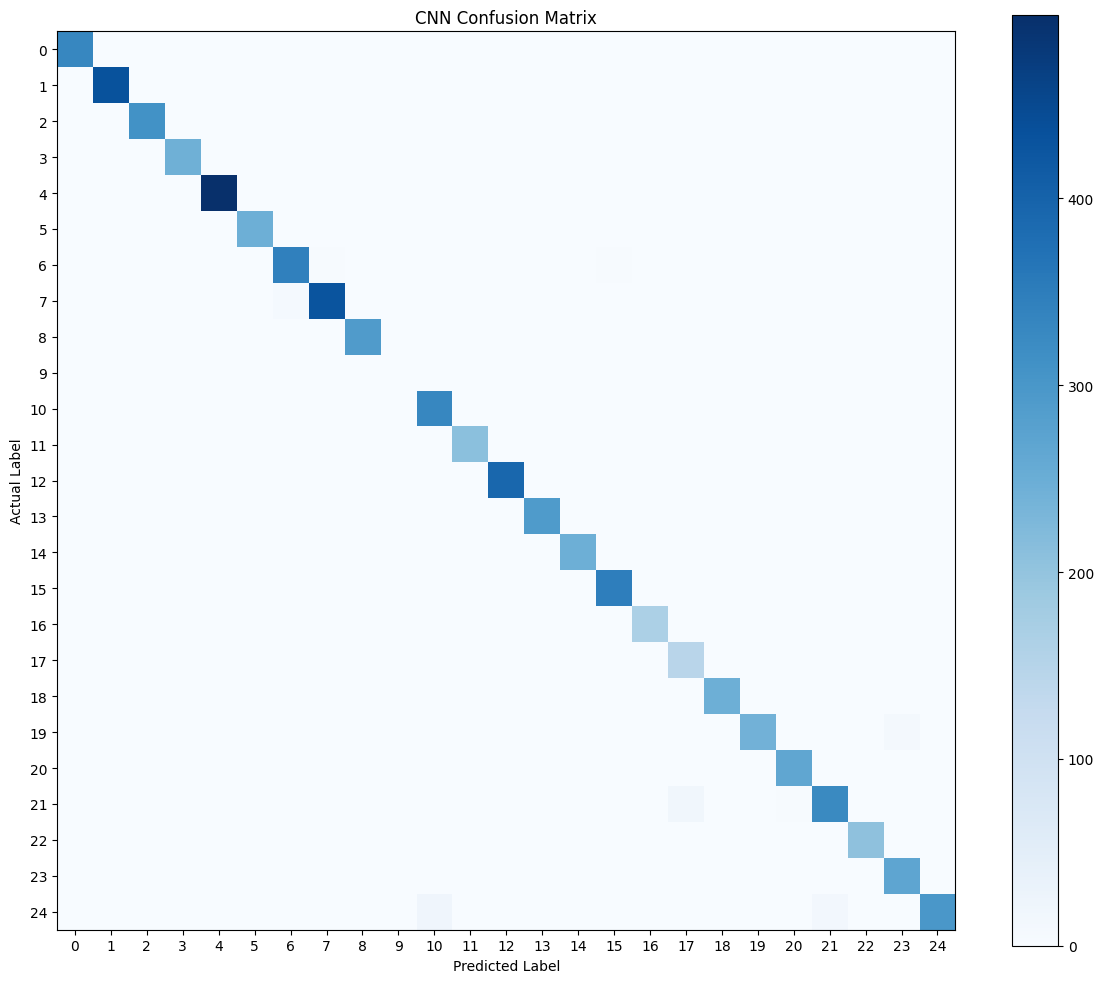

In [19]:
cm = confusion_matrix(
    y_test,
    predicted_labels,
    labels=list(range(25))
)

plt.figure(figsize=(12, 10))

plt.imshow(
    cm,
    cmap="Blues"
)

plt.title("CNN Confusion Matrix")

plt.xlabel("Predicted Label")

plt.ylabel("Actual Label")

plt.colorbar()

plt.xticks(range(25))

plt.yticks(range(25))

plt.tight_layout()

plt.show()

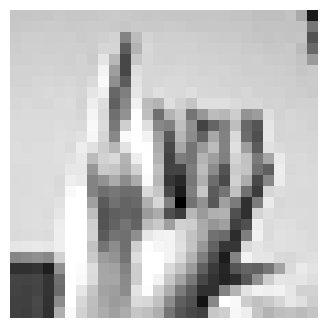

Actual Letter: I
Predicted Letter: I
Confidence: 100.0 %


In [20]:
# Select a random testing image

index = 10

image = X_test[index]

actual_label = int(y_test[index])

# Predict

prediction = model.predict(
    image.reshape(1, 28, 28, 1),
    verbose=0
)

predicted_label = int(
    np.argmax(prediction)
)

confidence = float(
    np.max(prediction) * 100
)

# Display image

plt.figure(figsize=(4, 4))

plt.imshow(
    image.reshape(28, 28),
    cmap="gray"
)

plt.axis("off")

plt.show()

print("Actual Letter:", label_to_letter(actual_label))

print("Predicted Letter:", label_to_letter(predicted_label))

print("Confidence:", round(confidence, 2), "%")

In [21]:
# Save trained model

model.save(
    "sign_language_cnn_model_fixed.keras"
)

print("\n================================")

print("FINAL MODEL SAVED SUCCESSFULLY")

print("================================")

print("Model Name: sign_language_cnn_model_fixed.keras")

print("Input Shape:", model.input_shape)

print("Output Shape:", model.output_shape)

print("Number of Output Classes:", model.output_shape[-1])


FINAL MODEL SAVED SUCCESSFULLY
Model Name: sign_language_cnn_model_fixed.keras
Input Shape: (None, 28, 28, 1)
Output Shape: (None, 25)
Number of Output Classes: 25


In [22]:
import os

print("Current folder:", os.getcwd())

for file in os.listdir():
    if file.endswith(".keras"):
        print("Model found:", os.path.abspath(file))

Current folder: c:\Users\navya\Desktop\Sign_Language_Recognition
Model found: c:\Users\navya\Desktop\Sign_Language_Recognition\sign_language_cnn_model.keras
Model found: c:\Users\navya\Desktop\Sign_Language_Recognition\sign_language_cnn_model_fixed.keras


In [23]:
import sys
import tensorflow as tf
import keras

print("Python:", sys.version)
print("Python path:", sys.executable)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

Python: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
Python path: c:\Users\navya\AppData\Local\Programs\Python\Python310\python.exe
TensorFlow: 2.21.0
Keras: 3.12.4


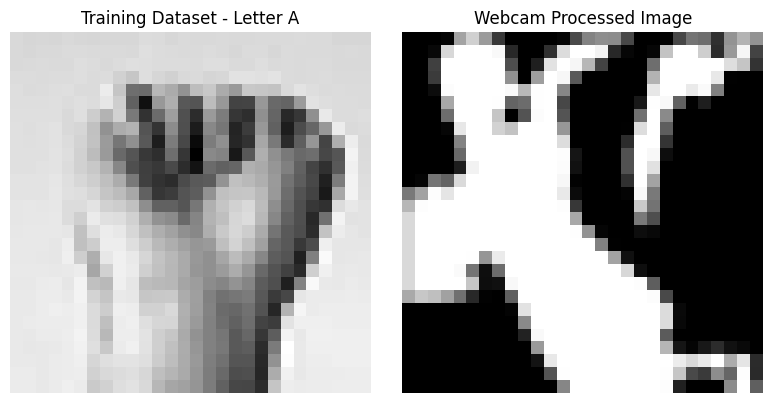

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os

# Load training dataset
df = pd.read_csv("dataset/sign_mnist_train.csv")

# Get one actual A image (label 0)
a_image = df[df["label"] == 0].iloc[0, 1:].values
a_image = a_image.reshape(28, 28)

# Load webcam processed image
webcam_image = cv2.imread(
    "debug_webcam.png",
    cv2.IMREAD_GRAYSCALE
)

# Display comparison
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(a_image, cmap="gray")
plt.title("Training Dataset - Letter A")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(webcam_image, cmap="gray")
plt.title("Webcam Processed Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
import sys
import tensorflow as tf
import keras

print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

Python: 3.10.11 (tags/v3.10.11:7d4cc5a, Apr  5 2023, 00:38:17) [MSC v.1929 64 bit (AMD64)]
TensorFlow: 2.21.0
Keras: 3.12.4


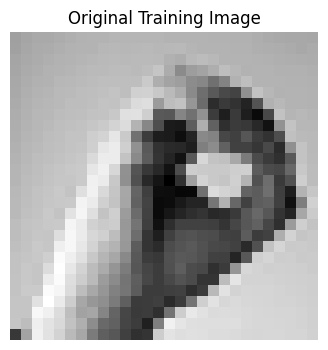

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(4, 4))
plt.imshow(X_train[0].reshape(28, 28), cmap="gray")
plt.title("Original Training Image")
plt.axis("off")
plt.show()

In [28]:
print("Test Accuracy:")
print(model.evaluate(X_test, y_test, verbose=0))

Test Accuracy:
[0.04027043282985687, 0.9895426630973816]


In [29]:
import numpy as np

predictions = model.predict(X_test)

y_pred = np.argmax(predictions, axis=1)

from sklearn.metrics import accuracy_score, classification_report

print("Test Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(y_test, y_pred))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
Test Accuracy: 0.989542665923034
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       331
           1       1.00      1.00      1.00       432
           2       1.00      1.00      1.00       310
           3       1.00      1.00      1.00       245
           4       1.00      1.00      1.00       498
           5       1.00      1.00      1.00       247
           6       0.98      0.99      0.98       348
           7       1.00      0.98      0.99       436
           8       1.00      1.00      1.00       288
          10       0.94      1.00      0.97       331
          11       1.00      1.00      1.00       209
          12       1.00      0.99      1.00       394
          13       1.00      1.00      1.00       291
          14       1.00      1.00      1.00       246
          15       0.99      1.00      1.00       347
          16       1.00      1.00      1.00       164
       

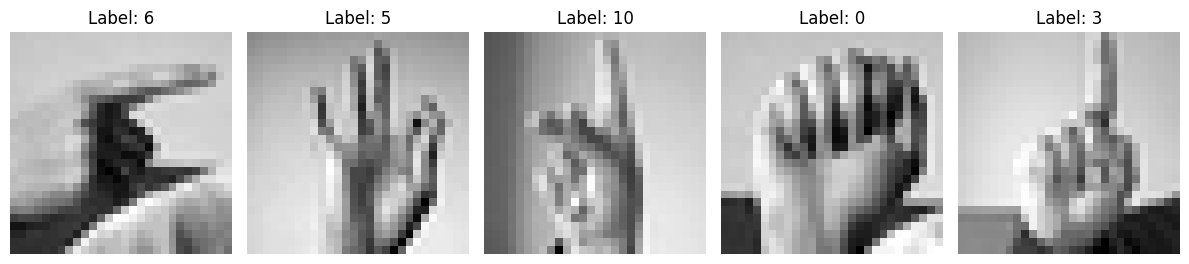

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y_test.iloc[i] if hasattr(y_test, 'iloc') else y_test[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

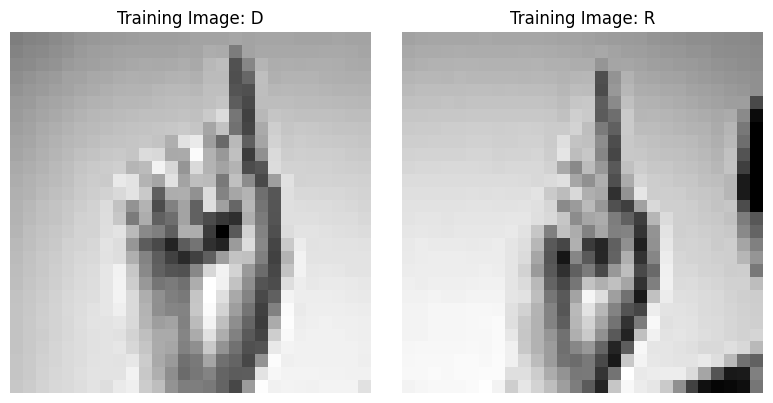

In [31]:
import matplotlib.pyplot as plt
import numpy as np

letters = ["D", "R"]

plt.figure(figsize=(8, 4))

for i, letter in enumerate(letters):

    label = ord(letter) - 65

    images = X_train[y_train == label]

    plt.subplot(1, 2, i + 1)
    plt.imshow(images[0].reshape(28, 28), cmap="gray")
    plt.title(f"Training Image: {letter}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Actual Letter: D
Predicted Letter: D
Confidence: 100.0 %


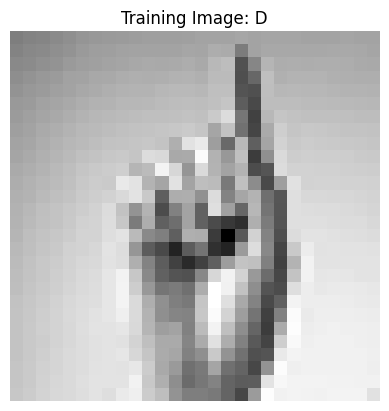

In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Find one D image from training data
d_indices = np.where(np.array(y_train) == 3)[0]

# Select the first D image
sample = X_train[d_indices[0]:d_indices[0] + 1]

# Predict
prediction = model.predict(sample, verbose=0)

predicted_label = np.argmax(prediction)
predicted_letter = chr(predicted_label + 65)

print("Actual Letter: D")
print("Predicted Letter:", predicted_letter)
print("Confidence:", round(np.max(prediction) * 100, 2), "%")

# Display image
plt.imshow(sample[0].reshape(28, 28), cmap="gray")
plt.title("Training Image: D")
plt.axis("off")
plt.show()

Actual Letter: D
Predicted Letter: D
Confidence: 100.0 %


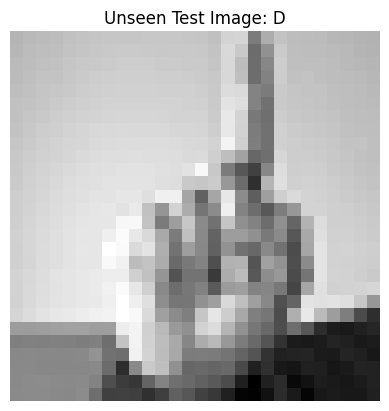

In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Find D images in the test dataset
d_indices = np.where(np.array(y_test) == 3)[0]

# Select an unseen D image
sample_index = d_indices[0]
sample = X_test[sample_index:sample_index + 1]

# Predict
prediction = model.predict(sample, verbose=0)

predicted_label = np.argmax(prediction)
predicted_letter = chr(predicted_label + 65)

print("Actual Letter: D")
print("Predicted Letter:", predicted_letter)
print("Confidence:", round(np.max(prediction) * 100, 2), "%")

plt.imshow(sample[0].reshape(28, 28), cmap="gray")
plt.title("Unseen Test Image: D")
plt.axis("off")
plt.show()

In [34]:
print("Training image:")
print("Minimum:", X_train[0].min())
print("Maximum:", X_train[0].max())
print("Mean:", X_train[0].mean())

import cv2

debug = cv2.imread("debug_webcam.png", cv2.IMREAD_GRAYSCALE)

print("\nUploaded image:")
print("Minimum:", debug.min())
print("Maximum:", debug.max())
print("Mean:", debug.mean())

Training image:
Minimum: 0.08627451
Maximum: 0.9137255
Mean: 0.5929822

Uploaded image:
Minimum: 60
Maximum: 255
Mean: 229.60204081632654


In [35]:
for i in range(5):
    print(
        f"Image {i}:",
        "Mean =", round(float(X_train[i].mean()), 3),
        "Min =", round(float(X_train[i].min()), 3),
        "Max =", round(float(X_train[i].max()), 3)
    )

Image 0: Mean = 0.593 Min = 0.086 Max = 0.914
Image 1: Mean = 0.709 Min = 0.176 Max = 0.918
Image 2: Mean = 0.437 Min = 0.0 Max = 0.863
Image 3: Mean = 0.611 Min = 0.224 Max = 0.969
Image 4: Mean = 0.276 Min = 0.0 Max = 0.725


In [36]:
import numpy as np

print("FULL TRAINING DATASET")

print("Mean:", X_train.mean())
print("Standard Deviation:", X_train.std())
print("Minimum:", X_train.min())
print("Maximum:", X_train.max())

print("\nUPLOADED IMAGE")

debug = cv2.imread("debug_webcam.png", cv2.IMREAD_GRAYSCALE)

debug = cv2.resize(debug, (28, 28))
debug = debug.astype("float32") / 255.0

print("Mean:", debug.mean())
print("Standard Deviation:", debug.std())
print("Minimum:", debug.min())
print("Maximum:", debug.max())

FULL TRAINING DATASET
Mean: 0.62478036
Standard Deviation: 0.19115654
Minimum: 0.0
Maximum: 1.0

UPLOADED IMAGE
Mean: 0.9004001
Standard Deviation: 0.15632272
Minimum: 0.23529412
Maximum: 1.0


Predicted Letter: N
Confidence: 94.76 %


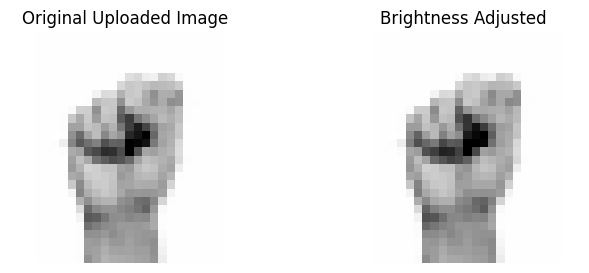

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

debug = cv2.imread("debug_webcam.png", cv2.IMREAD_GRAYSCALE)

debug = cv2.resize(debug, (28, 28))
debug = debug.astype("float32") / 255.0

# Adjust brightness to match training dataset mean
adjusted = debug - debug.mean() + X_train.mean()
adjusted = np.clip(adjusted, 0, 1)

# Prepare image for prediction
test_image = adjusted.reshape(1, 28, 28, 1)

# Predict
prediction = model.predict(test_image, verbose=0)

predicted_label = np.argmax(prediction)
predicted_letter = chr(predicted_label + 65)

print("Predicted Letter:", predicted_letter)
print("Confidence:", round(float(np.max(prediction)) * 100, 2), "%")

plt.figure(figsize=(8, 3))

plt.subplot(1, 2, 1)
plt.imshow(debug, cmap="gray")
plt.title("Original Uploaded Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(adjusted.squeeze(), cmap="gray")
plt.title("Brightness Adjusted")
plt.axis("off")

plt.show()

In [41]:
for letter in ["D", "R", "N"]:
    image_path = f"test_images/{letter}.png"

    image = cv2.imread(image_path)

    # Use the same hand detection and preprocessing
    # that you currently use in app.py.

    # Compare original and brightness-adjusted predictions.

In [42]:
import cv2
import numpy as np
import tensorflow as tf

# Load the exact model used by Flask
saved_model = tf.keras.models.load_model(
    "sign_language_cnn_model_fixed.keras",
    compile=False
)

# Read the processed image saved by app.py
image = cv2.imread(
    "debug_webcam.png",
    cv2.IMREAD_GRAYSCALE
)

# Restore the 28x28 image
image = cv2.resize(image, (28, 28))

# Normalize
image = image.astype("float32") / 255.0

# Prepare input
image = image.reshape(1, 28, 28, 1)

# Predict
predictions = saved_model.predict(image, verbose=0)[0]

# Display top 5 predictions
top_indices = np.argsort(predictions)[::-1][:5]

for index in top_indices:
    letter = chr(index + 65)

    print(
        letter,
        round(float(predictions[index]) * 100, 2),
        "%"
    )

N 99.57 %
M 0.37 %
S 0.03 %
A 0.01 %
Q 0.0 %


In [43]:
import cv2
import numpy as np
import tensorflow as tf

saved_model = tf.keras.models.load_model(
    "sign_language_cnn_model_fixed.keras",
    compile=False
)

image = cv2.imread(
    "debug_webcam.png",
    cv2.IMREAD_GRAYSCALE
)

image = cv2.resize(image, (28, 28))
image = image.astype("float32") / 255.0
image = image.reshape(1, 28, 28, 1)

predictions = saved_model.predict(image, verbose=0)[0]

top_indices = np.argsort(predictions)[::-1][:5]

print("Actual Letter: K")

for index in top_indices:
    print(
        chr(index + 65),
        round(float(predictions[index]) * 100, 2),
        "%"
    )

Actual Letter: K
T 79.04 %
D 9.61 %
V 4.57 %
L 4.55 %
F 1.93 %


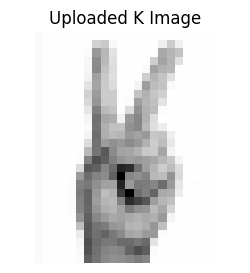

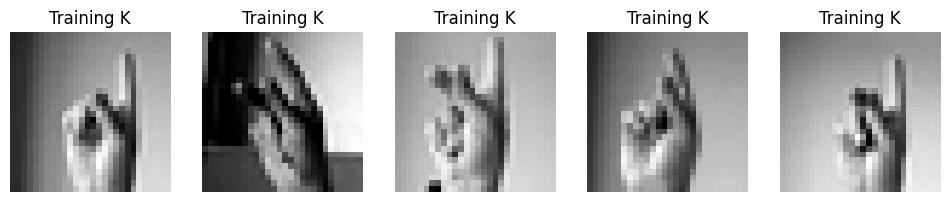

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# Display the processed K image
plt.figure(figsize=(3, 3))
plt.imshow(image[0].squeeze(), cmap="gray")
plt.title("Uploaded K Image")
plt.axis("off")
plt.show()

# Display 5 training images belonging to K
k_label = 10
k_indices = np.where(y_train == k_label)[0][:5]

plt.figure(figsize=(12, 3))

for i, idx in enumerate(k_indices):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_train[idx].squeeze(), cmap="gray")
    plt.title("Training K")
    plt.axis("off")

plt.show()

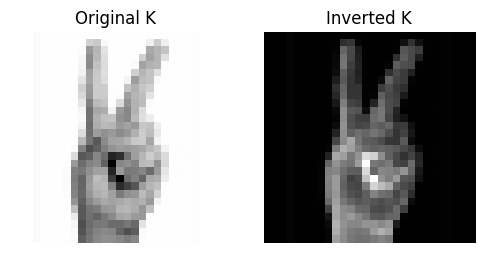

W 56.94 %
Q 16.18 %
K 15.35 %
B 11.38 %
U 0.06 %


In [45]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load processed uploaded image
debug = cv2.imread("debug_webcam.png", cv2.IMREAD_GRAYSCALE)

# Resize to model input size
debug = cv2.resize(debug, (28, 28))

# Normalize
debug = debug.astype("float32") / 255.0

# Invert image
inverted = 1.0 - debug

# Display original and inverted images
plt.figure(figsize=(6, 3))

plt.subplot(1, 2, 1)
plt.imshow(debug, cmap="gray")
plt.title("Original K")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(inverted, cmap="gray")
plt.title("Inverted K")
plt.axis("off")

plt.show()

# Predict using inverted image
test_image = inverted.reshape(1, 28, 28, 1)

predictions = saved_model.predict(test_image, verbose=0)[0]

top_indices = np.argsort(predictions)[::-1][:5]

for index in top_indices:
    if index != 9:
        print(chr(index + 65), round(float(predictions[index]) * 100, 2), "%")

In [46]:
# Adjust brightness to match training data mean
adjusted = debug - debug.mean() + X_train.mean()
adjusted = np.clip(adjusted, 0, 1)

test_image = adjusted.reshape(1, 28, 28, 1)

predictions = saved_model.predict(test_image, verbose=0)[0]

top_indices = np.argsort(predictions)[::-1][:5]

for index in top_indices:
    if index != 9:
        print(chr(index + 65), round(float(predictions[index]) * 100, 2), "%")

V 48.5 %
D 45.26 %
F 2.6 %
L 1.99 %
T 1.62 %


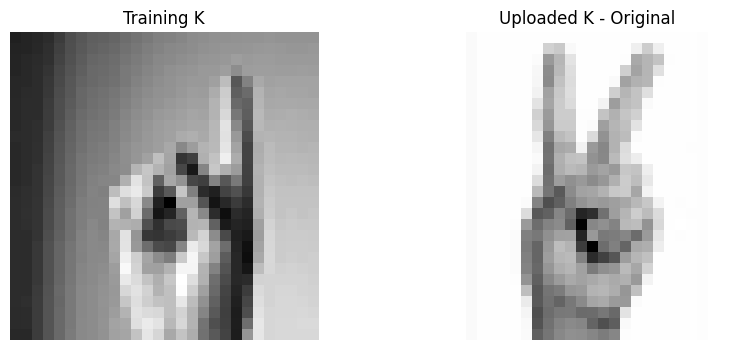

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(X_train[y_train == 10][0].squeeze(), cmap="gray")
plt.title("Training K")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(debug, cmap="gray")
plt.title("Uploaded K - Original")
plt.axis("off")

plt.show()

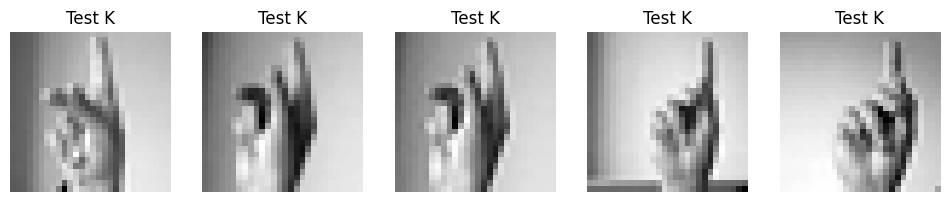

In [48]:
import matplotlib.pyplot as plt
import numpy as np

k_indices = np.where(y_test == 10)[0][:5]

plt.figure(figsize=(12, 3))

for i, idx in enumerate(k_indices):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title("Test K")
    plt.axis("off")

plt.show()

In [49]:
k_index = np.where(y_test == 10)[0][0]

test_k = X_test[k_index].reshape(1, 28, 28, 1)

prediction = saved_model.predict(test_k, verbose=0)[0]

predicted_label = np.argmax(prediction)

print("Actual: K")
print("Predicted:", chr(predicted_label + 65))
print("Confidence:", round(float(prediction[predicted_label]) * 100, 2), "%")

Actual: K
Predicted: K
Confidence: 100.0 %
